In [1]:
2+2

4

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
movies = pd.read_csv("movies_cleaned.csv")

print("Dataset Shape:", movies.shape)
movies.head()

Dataset Shape: (2503, 12)


,movie_id,title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,status,overview
0,157336,Interstellar,en,2014-11-05,169,165000000.0,7.466067e+08,73.0452,8.484,40566,Released,The adventures of a group of explorers who mak...
1,27205,Inception,en,2010-07-15,148,160000000.0,8.390306e+08,55.8497,8.400,39727,Released,"Cobb, a skilled thief who commits corporate es..."
2,24428,The Avengers,en,2012-04-25,143,220000000.0,1.518816e+09,72.2515,8.062,38993,Released,When an unexpected enemy emerges and threatens...
3,155,The Dark Knight,en,2008-07-16,152,185000000.0,1.004558e+09,60.5510,8.534,36255,Released,Batman raises the stakes in his war on crime. ...
4,19995,Avatar,en,2009-12-16,162,237000000.0,2.923706e+09,48.1996,7.610,34348,Released,"In the 22nd century, a paraplegic Marine is di..."


1. Distribution of Movie Budgets

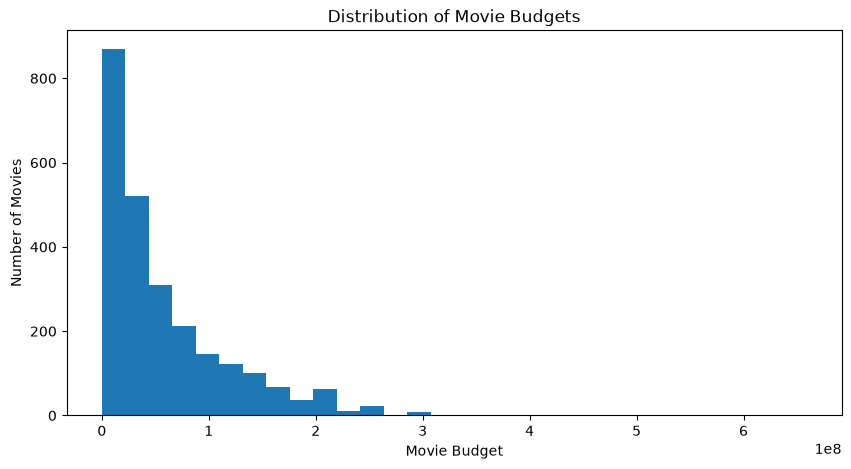

In [4]:
plt.figure(figsize=(10, 5))

plt.hist(movies["budget"], bins=30)

plt.title("Distribution of Movie Budgets")
plt.xlabel("Movie Budget")
plt.ylabel("Number of Movies")

plt.show()

### Insight 1: Distribution of Movie Budgets

The histogram shows that most movies in the dataset are concentrated in the lower budget ranges. The number of movies decreases as the budget increases, while only a small number of movies have very high budgets. This indicates a right-skewed distribution of movie budgets.

2. Distribution of Runtimes


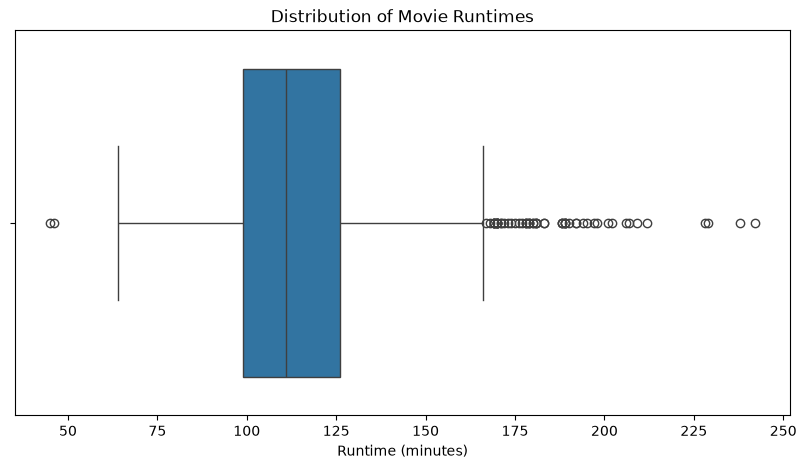

In [5]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=movies["runtime"])

plt.title("Distribution of Movie Runtimes")
plt.xlabel("Runtime (minutes)")

plt.show()

**Insight 2: Distribution of Movie Runtimes**

The box plot shows that most movies have runtimes between approximately 100 and 125 minutes. A few movies have much longer runtimes, appearing as outliers beyond 170 minutes. This indicates that while most movies have a runtime close to two hours, some movies are considerably longer.

## 3. Distribution of Movie Ratings

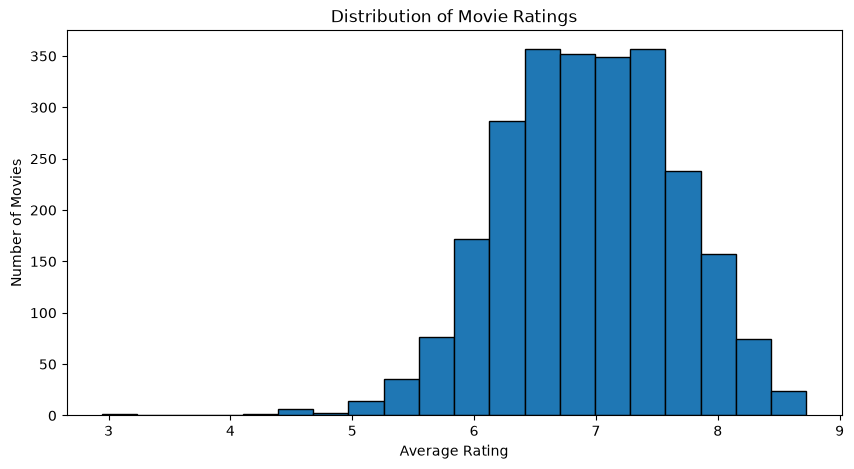

In [6]:
plt.figure(figsize=(10, 5))

plt.hist(movies["vote_average"], bins=20, edgecolor="black")

plt.title("Distribution of Movie Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")

plt.show()

**Insight 3: Distribution of Movie Ratings**

The histogram shows that most movies have average ratings between approximately 6.0 and 7.5. The highest concentration of movies is around ratings 6.5 to 7.5, while very few movies have ratings below 5.0. This suggests that most movies in the dataset have moderate to good audience ratings.

## 4. Number of Movies per Genre


In [7]:

# Load the movie-genre relationship data
movie_genres = pd.read_csv("movie_genres_cleaned.csv")

genres = pd.read_csv("genres_cleaned.csv")

print(movie_genres.columns.tolist())
print(genres.columns.tolist())


['movie_id', 'genre_id']
['genre_id', 'genre_name']


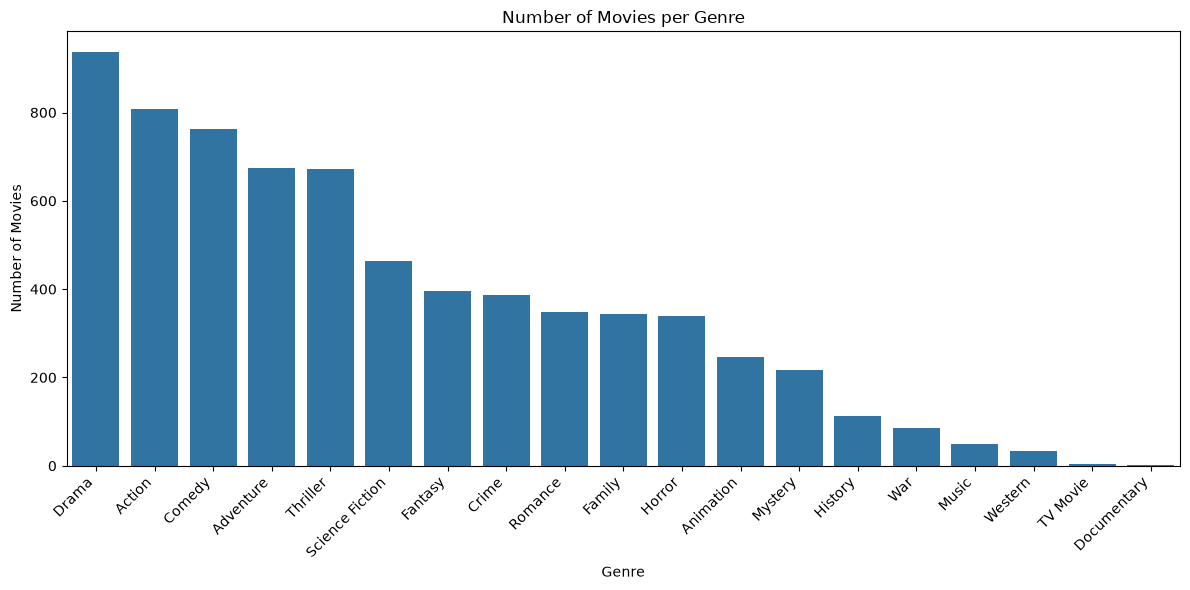

In [8]:

movies_genres = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)


genre_counts = movies_genres["genre_name"].value_counts()

plt.figure(figsize=(12, 6))
sns.barplot(x=genre_counts.index, y=genre_counts.values)

plt.title("Number of Movies per Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


**Insight 4: Number of Movies per Genre**

The bar chart shows that Drama has the highest number of movie-genre records, followed by Action and Comedy. Documentary and TV Movie have very few records compared with the leading genres. This indicates that Drama, Action, and Comedy are the most represented genres in this dataset.

## 5. Relationship Between Movie Budget and Revenue

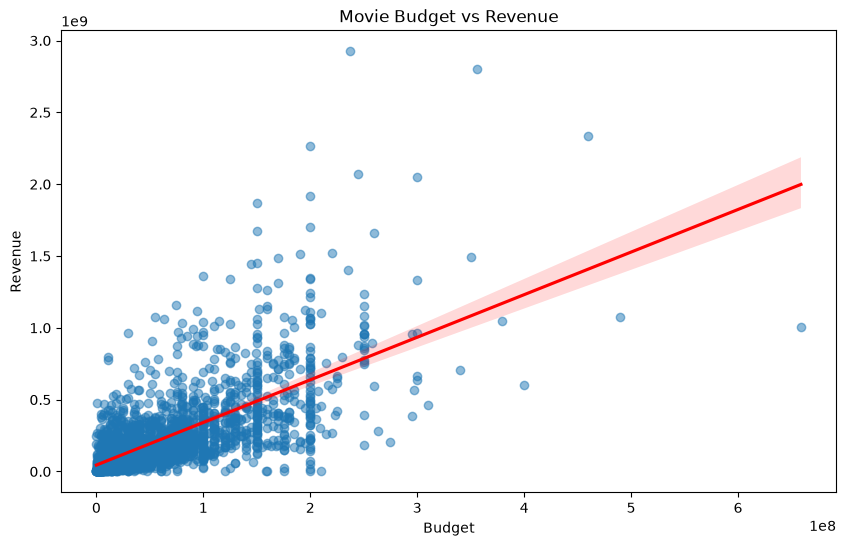

In [9]:

# Remove movies with unknown budget or revenue values (zero)
budget_revenue = movies[
    (movies["budget"] > 0) &
    (movies["revenue"] > 0)
]

plt.figure(figsize=(10, 6))

sns.regplot(
    data=budget_revenue,
    x="budget",
    y="revenue",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")

plt.show()


**Insight 5: Relationship Between Movie Budget and Revenue**

The scatter plot shows a positive relationship between movie budget and revenue. In general, movies with higher budgets tend to generate higher revenues, as indicated by the upward-sloping red trend line. However, the wide spread of data points shows that a higher budget does not always guarantee higher revenue, and some movies earn much more than others with similar budgets.

## 6. Relationship Between Movie Popularity and Vote Count

In [10]:
import plotly
import plotly.io as pio

print("Plotly version:", plotly.__version__)
print("Default renderer:", pio.renderers.default)

Plotly version: 7.1.0
Default renderer: vscode


In [11]:
import plotly.io as pio

pio.renderers.default = "vscode"
print("Renderer set to:", pio.renderers.default)

Renderer set to: vscode


In [3]:
import pandas as pd

movies = pd.read_csv("movies_cleaned.csv")

print("Dataset Shape:", movies.shape)
movies.head()

Dataset Shape: (2503, 12)


,movie_id,title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,status,overview
0,157336,Interstellar,en,2014-11-05,169,165000000.0,7.466067e+08,73.0452,8.484,40566,Released,The adventures of a group of explorers who mak...
1,27205,Inception,en,2010-07-15,148,160000000.0,8.390306e+08,55.8497,8.400,39727,Released,"Cobb, a skilled thief who commits corporate es..."
2,24428,The Avengers,en,2012-04-25,143,220000000.0,1.518816e+09,72.2515,8.062,38993,Released,When an unexpected enemy emerges and threatens...
3,155,The Dark Knight,en,2008-07-16,152,185000000.0,1.004558e+09,60.5510,8.534,36255,Released,Batman raises the stakes in his war on crime. ...
4,19995,Avatar,en,2009-12-16,162,237000000.0,2.923706e+09,48.1996,7.610,34348,Released,"In the 22nd century, a paraplegic Marine is di..."


In [5]:

import plotly.express as px

fig = px.scatter(
    movies,
    x="vote_count",
    y="popularity",
    title="Movie Popularity vs Vote Count",
    labels={
        "vote_count": "Vote Count",
        "popularity": "Popularity"
    },
    hover_data=["title"]
)

fig.show(renderer="vscode")


**Insight 6: Relationship Between Movie Popularity and Vote Count**

The scatter plot helps examine the relationship between audience vote counts and movie popularity. Movies with different vote counts show varying popularity levels, suggesting that vote count alone may not fully explain a movie's popularity. The distribution of points helps identify whether a clear relationship exists between these two variables.

In [8]:
import pandas as pd

movies = pd.read_csv("movies_cleaned.csv")
movie_genres = pd.read_csv("movie_genres_cleaned.csv")
genres = pd.read_csv("genres_cleaned.csv")

movies_genres = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)

print("Movies:", movies.shape)
print("Movie genres:", movie_genres.shape)
print("Genres:", genres.shape)
print("Joined data:", movies_genres.shape)

Movies: (2503, 12)
Movie genres: (6878, 2)
Genres: (19, 2)
Joined data: (6878, 3)


## 7. Average Movie Rating by Genre

In [9]:

rating_by_genre = movies_genres.merge(
    movies[["movie_id", "vote_average"]],
    on="movie_id",
    how="left"
)

rating_by_genre = (
    rating_by_genre.groupby("genre_name")["vote_average"]
    .mean()
    .reset_index()
    .sort_values("vote_average", ascending=False)
)


fig = px.bar(
    rating_by_genre,
    x="genre_name",
    y="vote_average",
    title="Average Movie Rating by Genre",
    labels={
        "genre_name": "Genre",
        "vote_average": "Average Rating"
    }
)

fig.show(renderer="vscode")


**Insight 7: Average Movie Rating by Genre**

The chart shows that War, History, and Music have the highest average movie ratings in this dataset. Horror and Action have comparatively lower average ratings. However, the differences between genres are relatively small, suggesting that average ratings are fairly similar across genres.

## 8. Number of Movies Released per Year

In [10]:

movies["release_date"] = pd.to_datetime(
    movies["release_date"],
    errors="coerce"
)

movies["release_year"] = movies["release_date"].dt.year

movies_per_year = (
    movies.groupby("release_year")["movie_id"]
    .count()
    .reset_index(name="movie_count")
    .sort_values("release_year")
)

fig = px.bar(
    movies_per_year,
    x="release_year",
    y="movie_count",
    title="Number of Movies Released per Year",
    labels={
        "release_year": "Release Year",
        "movie_count": "Number of Movies"
    }
)

fig.show(renderer="vscode")


**Insight 8: Number of Movies Released per Year**

The chart shows that the number of movies in the dataset increased significantly from the early 2000s, reaching its highest point around 2016. After this peak, the number of movies declines in the following years. This pattern may reflect the growth of movie production over time, while the lower counts in recent years may be due to incomplete data coverage.

## 9. Correlation Heatmap of Movie Features

In [11]:


correlation_columns = [
    "budget",
    "revenue",
    "runtime",
    "popularity",
    "vote_average",
    "vote_count"
]

correlation_matrix = movies[correlation_columns].corr()

fig = px.imshow(
    correlation_matrix,
    text_auto=".2f",
    title="Correlation Heatmap of Movie Features",
    color_continuous_scale="RdBu_r",
    aspect="auto"
)

fig.show(renderer="vscode")


**Insight 9: Correlation Between Movie Features**

The heatmap shows a positive correlation of 0.68 between movie budget and revenue, indicating that higher-budget movies tend to generate higher revenue. Revenue also has a positive correlation of 0.61 with vote count, suggesting that movies earning more revenue often receive more audience votes. In contrast, budget and average rating have a weak negative correlation of -0.13, indicating that higher budgets do not necessarily lead to better audience ratings.

## 10. Relationship Between Budget, Revenue, Popularity and Ratings

In [12]:

fig = px.scatter(
    movies,
    x="budget",
    y="revenue",
    color="vote_average",
    size="vote_count",
    hover_name="title",
    title="Movie Budget vs Revenue by Rating",
    labels={
        "budget": "Budget",
        "revenue": "Revenue",
        "vote_average": "Average Rating",
        "vote_count": "Vote Count"
    }
)

fig.show(renderer="vscode")


**Insight 10: Relationship Between Budget, Revenue, Popularity and Ratings**

The scatter plot shows that movies with larger budgets often generate higher revenues, although there are exceptions. The color distribution indicates that movies across different rating levels can achieve high revenue. Larger circles represent movies with higher vote counts, showing that audience engagement varies across movies with similar budgets. Overall, a higher budget does not guarantee a higher rating or revenue.